# Lecture 11: Ensembles

Can combining models improve predictions? We will compare ensembles on the Adult income dataset and inspect how they combine predictions.

Our workflow in this lecture: 

reserve a test set $\to$ establish baselines $\to$ build a random forest $\to$ compare boosting models $\to$ combine models with voting and stacking. By the end, you should be able to explain the sources of forest randomness, distinguish averaging from boosting, and explain why stacking needs out-of-fold predictions.

## Setup and imports

Run this notebook from `content/classes/varada` using this directory's `.venv` kernel. Place `adult.csv` in `data/` and run the cells in order. The boosting comparison also requires XGBoost, LightGBM, and CatBoost. From this directory, install them into the demo environment with `uv pip install --python .venv/bin/python xgboost lightgbm catboost` before class.

We use three stratified CV folds and small, explicit model configurations to keep the live demo manageable. These are starting configurations, not a tuning competition. The test set stays reserved throughout.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

%matplotlib inline

DATA_DIR = Path.cwd() / "data"
data_path = DATA_DIR / "adult.csv"
if not data_path.is_file():
    raise FileNotFoundError(f"Place adult.csv at {data_path} and run from content/classes/varada.")


## 1. Why combine predictions?

An **ensemble** combines predictions from multiple models. Useful models that make different mistakes may improve on one model alone.

**Predict:** A house sells for $\$500,000$. Two models predict $\$460,000$ and $\$520,000$. What does their average predict? Would averaging help if both predicted $\$460,000$?

The first average is $\$490,000$: the errors partly cancel. The second stays at $\$460,000$. Diversity can help, but validation results must show whether the combination improves predictions.

## 2. Load, split, and review preprocessing

Each Adult dataset row describes a person; the target is whether recorded annual income exceeds $\$50,000$. This is a historical prediction exercise using 1994 census data.

Reserve 20% for testing. Replacing `?` with `np.nan` is a fixed rule; learned preprocessing stays inside each pipeline.

In [2]:
adult_df_large = pd.read_csv(data_path)
train_df, test_df = train_test_split(adult_df_large, test_size=0.2, random_state=42)
train_df_nan = train_df.replace("?", np.nan)
test_df_nan = test_df.replace("?", np.nan)
train_df_nan.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
5514,26,Private,256263,HS-grad,9,Never-married,Craft-repair,Not-in-family,White,Male,0,0,25,United-States,<=50K
19777,24,Private,170277,HS-grad,9,Never-married,Other-service,Not-in-family,White,Female,0,0,35,United-States,<=50K
10781,36,Private,75826,Bachelors,13,Divorced,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32240,22,State-gov,24395,Some-college,10,Married-civ-spouse,Adm-clerical,Wife,White,Female,0,0,20,United-States,<=50K
9876,31,Local-gov,356689,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,40,United-States,<=50K


### Reuse familiar feature transformations

| Features | Transformation |
|---|---|
| Age, capital gains/losses, hours per week | Scale for the logistic-regression comparison; trees do not need scaling |
| Workclass, marital status, occupation, relationship, native country | Fill missing entries with `missing`, then one-hot encode |
| Education | Ordinal encode using the dataset's code order |
| Recorded sex | Binary indicator |
| `education.num`, `fnlwgt`, `race` | Drop duplicate education code, census sampling weight, and race |

We use unweighted training. Including recorded sex and omitting race are demo choices; they do not establish fairness. Aggregate accuracy can hide differences across groups.

In [3]:
numeric_features = ["age", "capital.gain", "capital.loss", "hours.per.week"]

categorical_features = [
    "workclass",
    "marital.status",
    "occupation",
    "relationship",
    "native.country",
]

ordinal_features = ["education"]
binary_features = ["sex"]
drop_features = ["fnlwgt", "race", "education.num"]
target_column = "income"

Education follows the dataset's `education.num` order. This is a coding convention. A linear model assumes equal effects per code step; a tree can split at different thresholds. One-hot encoding would be another representation to compare.

In [4]:
education_levels = [
    "Preschool",
    "1st-4th",
    "5th-6th",
    "7th-8th",
    "9th",
    "10th",
    "11th",
    "12th",
    "HS-grad",
    "Some-college",
    "Assoc-voc",
    "Assoc-acdm",
    "Bachelors",
    "Masters",
    "Prof-school",
    "Doctorate",
]

In [5]:
# Check that the explicit order matches the dataset's education codes.
education_order = (
    train_df[["education", "education.num"]]
    .drop_duplicates()
    .sort_values("education.num")["education"]
    .tolist()
)
assert education_levels == education_order

### Build the preprocessor

**Discuss:** Why must this transformer be inside the pipeline during CV?

Each fold must learn preprocessing from its own fitting rows. We use dense one-hot output for compatibility with the boosting models; unseen categories map to all-zero indicators.

In [6]:
numeric_transformer = StandardScaler()

ordinal_transformer = OrdinalEncoder(categories=[education_levels], dtype=int)

binary_transformer = make_pipeline(
    SimpleImputer(strategy="constant", fill_value="missing"),
    OneHotEncoder(drop="if_binary", dtype=int),
)
categorical_transformer = make_pipeline(
    SimpleImputer(strategy="constant", fill_value="missing"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
)

preprocessor = make_column_transformer(
    (numeric_transformer, numeric_features),
    (ordinal_transformer, ordinal_features),
    (binary_transformer, binary_features),
    (categorical_transformer, categorical_features),
    ("drop", drop_features),
    verbose_feature_names_out=False
)

In [7]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('standardscaler', ...), ('ordinalencoder', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for fe

Separate features and targets; leave the test set reserved.

In [8]:
X_train = train_df_nan.drop(columns=[target_column])
y_train = train_df_nan[target_column]

X_test = test_df_nan.drop(columns=[target_column])
y_test = test_df_nan[target_column]

**Predict:** What accuracy could a classifier achieve without using any features? Inspect the training class proportions.

In [9]:
train_df["income"].value_counts(normalize=True)

income
<=50K    0.757985
>50K     0.242015
Name: proportion, dtype: float64

The majority-class proportion gives a baseline. We use accuracy to focus on ensemble mechanics; choosing a metric for an application depends on the consequences of errors, as in lecture 9.

In [10]:
scoring_metric = "accuracy"

Encode the target as integers for compatibility with the external libraries. Fit the mapping on training labels only; feature encoding remains inside the pipelines.

In [11]:
label_encoder = LabelEncoder()
y_train_num = label_encoder.fit_transform(y_train)
y_test_num = label_encoder.transform(y_test)

In [12]:
pd.Series(label_encoder.classes_, name="Income label").rename_axis("Encoded target")

Encoded target
0    <=50K
1     >50K
Name: Income label, dtype: object

## 3. Establish baselines

Use the same three stratified folds, preprocessing, and accuracy metric for all candidates. Store fold scores and timings in `cv_results`.

`cross_validate` calls validation-fold accuracy `test_score`; it does **not** refer to our reserved test set.

In [13]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)
cv_splits = list(cv.split(X_train, y_train_num))
cv_results = {}

### Majority-class baseline

`DummyClassifier` predicts the most frequent fitting label. Record training scores too so we can compare training and validation performance.

In [14]:
dummy = DummyClassifier()
cv_results["Dummy"] = cross_validate(
    dummy, X_train, y_train_num, cv=cv_splits, return_train_score=True, scoring=scoring_metric
)

### Single decision tree

**Predict:** Will an unrestricted tree have similar training and validation accuracy?

In [15]:
pipe_dt = make_pipeline(preprocessor, DecisionTreeClassifier(random_state=123))
cv_results["decision tree"] = cross_validate(
    pipe_dt, X_train, y_train_num, cv=cv_splits, return_train_score=True, scoring=scoring_metric
)

### Keep one comparison table

This helper summarizes stored scores and timings without fitting models. Standard deviation describes variation across folds; it is not a confidence interval.

In [16]:
def comparison_table(cv_results):
    """Summarize stored fold scores and timings without fitting models."""
    return pd.DataFrame({
        name: {
            "mean training accuracy": scores["train_score"].mean(),
            "mean validation accuracy": scores["test_score"].mean(),
            "validation accuracy std": scores["test_score"].std(),
            "mean fit time (s)": scores["fit_time"].mean(),
            "mean score time (s)": scores["score_time"].mean(),
        }
        for name, scores in cv_results.items()
    }).T

In [17]:
comparison_table(cv_results)

,mean training accuracy,mean validation accuracy,validation accuracy std,mean fit time (s),mean score time (s)
Dummy,0.757985,0.757985,0.000049,0.002345,0.000364
decision tree,0.980421,0.817836,0.000829,0.059834,0.006982


**Discuss:** Does the tree improve on the dummy? How large is its training–validation gap?

Read validation accuracy alongside fold variation and fit time. A tiny score difference alone is weak evidence for choosing a slower model.

## 4. Random forests: average different trees

A forest averages predictions from independently trained trees. If every tree made the same predictions, averaging would change nothing.

**Predict:** How could we train different trees from the same dataset?

### Two sources of randomness

1. **Bootstrap rows:** each tree draws $n$ rows with replacement from the $n$ training rows. Some rows repeat; others are absent. Training on bootstrap samples and combining predictions is **bagging**.
2. **Sample features at each split:** choose the best split from a random subset of candidate features. This encourages trees to make different decisions.

For rows `[0, 1, 2, 3, 4, 5]`, one bootstrap sample might be `[1, 1, 3, 3, 3, 4]`.

**Discuss:** Why choose features again at every split rather than exclude a feature from an entire tree?

### Inspect three small trees

Fit three trees of depth two so we can read them. These size limits are for visualization. `clone` gives this demonstration its own preprocessor.

**Look for:** Do the trees use the same features and thresholds?

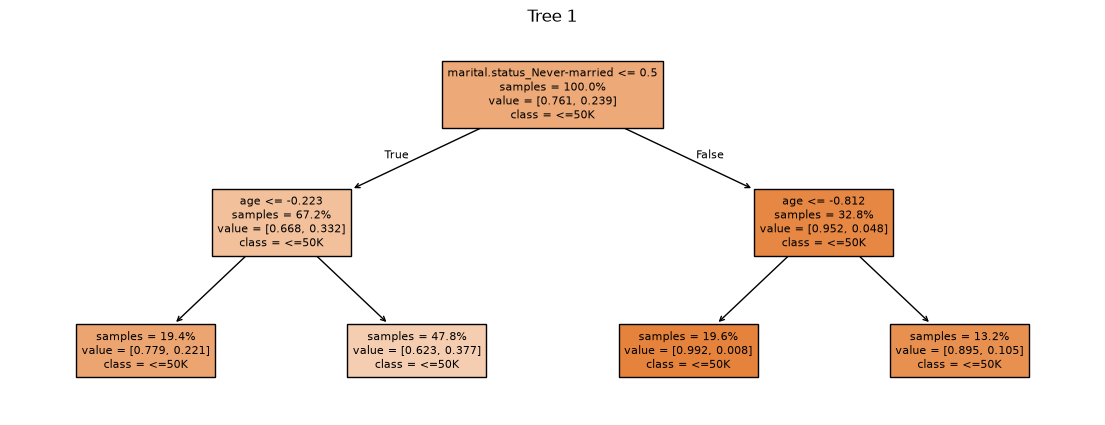

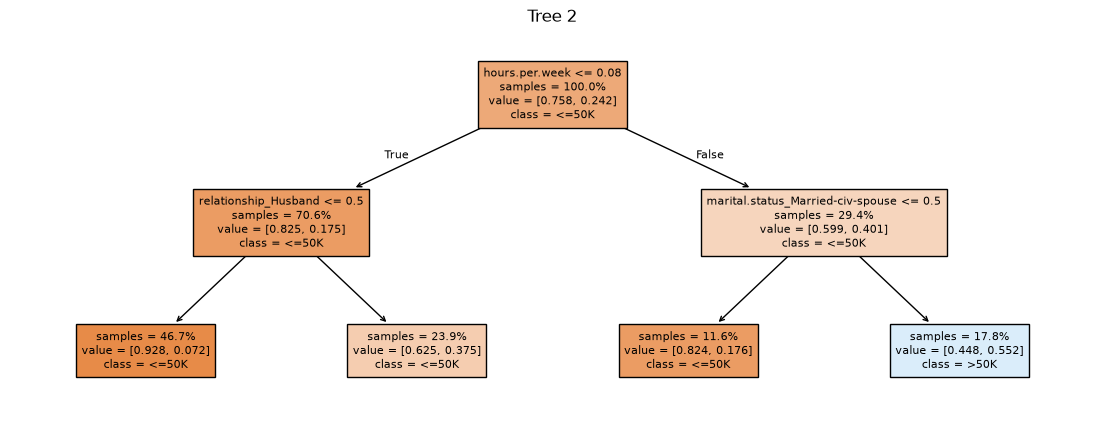

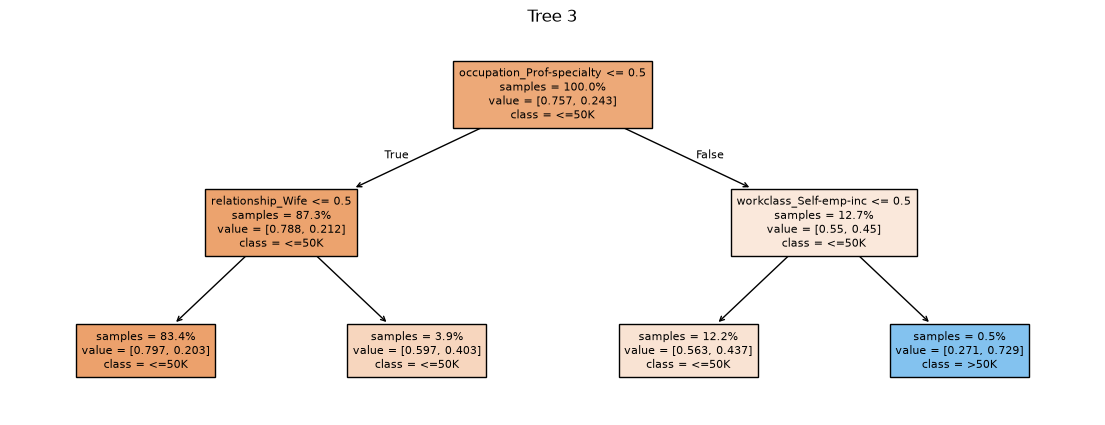

In [18]:
pipe_rf_demo = make_pipeline(
    clone(preprocessor),
    RandomForestClassifier(n_estimators=3, max_depth=2, random_state=123),
)
pipe_rf_demo.fit(X_train, y_train_num)
demo_preprocessor = pipe_rf_demo.named_steps["columntransformer"]
demo_forest = pipe_rf_demo.named_steps["randomforestclassifier"]
feature_names = demo_preprocessor.get_feature_names_out()

for i, tree in enumerate(demo_forest.estimators_, start=1):
    fig, ax = plt.subplots(figsize=(14, 5))
    plot_tree(
        tree, feature_names=feature_names,
        class_names=label_encoder.classes_.tolist(),
        filled=True, impurity=False, proportion=True, fontsize=8, ax=ax,
    )
    ax.set_title(f"Tree {i}")
    plt.show()

In [19]:
feature_names

array(['age', 'capital.gain', 'capital.loss', 'hours.per.week',
       'education', 'sex_Male', 'workclass_Federal-gov',
       'workclass_Local-gov', 'workclass_Never-worked',
       'workclass_Private', 'workclass_Self-emp-inc',
       'workclass_Self-emp-not-inc', 'workclass_State-gov',
       'workclass_Without-pay', 'workclass_missing',
       'marital.status_Divorced', 'marital.status_Married-AF-spouse',
       'marital.status_Married-civ-spouse',
       'marital.status_Married-spouse-absent',
       'marital.status_Never-married', 'marital.status_Separated',
       'marital.status_Widowed', 'occupation_Adm-clerical',
       'occupation_Armed-Forces', 'occupation_Craft-repair',
       'occupation_Exec-managerial', 'occupation_Farming-fishing',
       'occupation_Handlers-cleaners', 'occupation_Machine-op-inspct',
       'occupation_Other-service', 'occupation_Priv-house-serv',
       'occupation_Prof-specialty', 'occupation_Protective-serv',
       'occupation_Sales', 'occupation

Numeric split thresholds are in standardized units. Leaf `value` entries give class proportions in the displayed class order.

**Predict:** How will the forest combine the three trees' probabilities for one row?

We use a training row to inspect the arithmetic, not to estimate generalization.

In [20]:
demo_example = X_train.iloc[[0]]
transformed_example = demo_preprocessor.transform(demo_example)
tree_probabilities = np.vstack([
    tree.predict_proba(transformed_example)[0]
    for tree in demo_forest.estimators_
])
probability_table = pd.DataFrame(
    tree_probabilities,
    index=[f"Tree {i}" for i in range(1, 4)],
    columns=label_encoder.classes_,
)
probability_table.loc["Average"] = tree_probabilities.mean(axis=0)
probability_table.loc["Forest predict_proba"] = pipe_rf_demo.predict_proba(demo_example)[0]
probability_table

,<=50K,>50K
Tree 1,0.992222,0.007778
Tree 2,0.927500,0.072500
Tree 3,0.796607,0.203393
Average,0.905443,0.094557
Forest predict_proba,0.905443,0.094557


In [21]:
predicted_code = pipe_rf_demo.predict(demo_example)
label_encoder.inverse_transform(predicted_code)

array(['<=50K'], dtype=object)

The forest averages **class probabilities**, then selects the largest average. This can differ from voting on the trees' class labels.

For regression, `RandomForestRegressor` averages numerical predictions. Each tree is trained independently.

### Evaluate a larger forest

Remove the visualization depth limit and reuse our baseline folds. Trees can fit in parallel; keep the outer CV loop sequential.

In [22]:
pipe_rf = make_pipeline(
    clone(preprocessor),
    RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=123),
)
cv_results["random forest"] = cross_validate(
    pipe_rf, X_train, y_train_num, cv=cv_splits,
    return_train_score=True, scoring=scoring_metric,
)
comparison_table(cv_results)

,mean training accuracy,mean validation accuracy,validation accuracy std,mean fit time (s),mean score time (s)
Dummy,0.757985,0.757985,0.000049,0.002345,0.000364
decision tree,0.980421,0.817836,0.000829,0.059834,0.006982
random forest,0.980402,0.849278,0.001717,0.116253,0.020616


### Explore forest size

Compare the forest with the single tree: validation accuracy, training–validation gap, and computation time.

| Parameter | Effect |
|---|---|
| `n_estimators` | More trees stabilize the average, with more computation and memory |
| `max_depth` | Limit how detailed each tree can become |
| `min_samples_leaf` | Larger leaves discourage fitting very specific patterns |
| `max_features` | Fewer split candidates encourage diversity but may weaken trees |

**Predict:** Sketch training and validation accuracy as we add trees. Would increasing tree depth have the same effect?

Reuse the 100-tree result and compare a short list of sizes.

In [23]:
tree_count_results = {100: cv_results["random forest"]}
for n_trees in [1, 5, 25, 200]:
    candidate = clone(pipe_rf).set_params(randomforestclassifier__n_estimators=n_trees)
    tree_count_results[n_trees] = cross_validate(
        candidate, X_train, y_train_num, cv=cv_splits,
        return_train_score=True, scoring=scoring_metric,
    )

tree_count_summary = comparison_table(tree_count_results).sort_index()
tree_count_summary.index.name = "Number of trees"
tree_count_summary

,mean training accuracy,mean validation accuracy,validation accuracy std,mean fit time (s),mean score time (s)
Number of trees,,,,,
1,0.921203,0.805513,0.004481,0.032380,0.007407
5,0.963183,0.835995,0.003642,0.026540,0.019255
25,0.978540,0.846322,0.000527,0.049252,0.020410
100,0.980402,0.849278,0.001717,0.116253,0.020616
200,0.980421,0.851044,0.001451,0.189318,0.032299


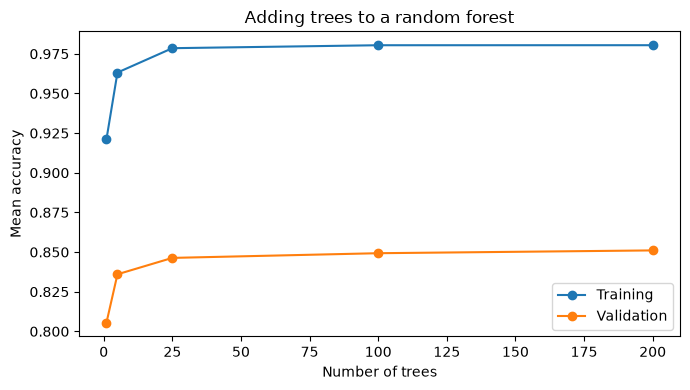

In [24]:
ax = tree_count_summary[
    ["mean training accuracy", "mean validation accuracy"]
].plot(marker="o", figsize=(7, 4))
ax.set(xlabel="Number of trees", ylabel="Mean accuracy", title="Adding trees to a random forest")
ax.legend(["Training", "Validation"])
plt.tight_layout()
plt.show()

**Discuss:** Where does the validation curve level off? Does the extra fit time seem worthwhile?

Adding trees averages more predictions from the same training procedure; deeper trees increase each tree's flexibility. More trees cannot remove errors shared by the whole forest.

**Discuss:** A 100-tree forest scores 0.99 on training and 0.85 on validation. Doubling the trees gives 0.99 and 0.851 at roughly twice the fit time. What would you try next?

Consider restricting depth or increasing leaf size, and use CV to check for either improvement or underfitting.

## 5. Boosting: learn successive corrections

A forest trains trees independently. Boosting builds trees **in sequence**, with each new tree correcting the current ensemble.

For squared-error regression:

1. Start with the mean training target.
2. Fit a small tree to residuals: actual − current prediction.
3. Add `learning_rate × correction`, then repeat.

**Predict:** If we predict 280 for a house worth 200, what is its residual? If a tree predicts a correction of −50 and the learning rate is 0.5, what is the updated prediction?

The invented prices below are in thousands of dollars.

In [25]:
from sklearn.tree import DecisionTreeRegressor

X_boost_demo = pd.DataFrame({"floor_area": [50, 70, 90, 110, 130, 150]})
y_boost_demo = np.array([200, 220, 260, 300, 340, 360], dtype=float)
initial_prediction = y_boost_demo.mean()
current_prediction = np.full(len(y_boost_demo), initial_prediction)
learning_rate = 0.5
boost_steps = pd.DataFrame({
    "floor area": X_boost_demo["floor_area"],
    "actual price": y_boost_demo,
    "initial prediction": current_prediction.copy(),
})
correction_trees = []
for step in range(1, 3):
    residuals = y_boost_demo - current_prediction
    tree = DecisionTreeRegressor(max_depth=1, random_state=123)
    tree.fit(X_boost_demo, residuals)
    correction = tree.predict(X_boost_demo)
    current_prediction = current_prediction + learning_rate * correction
    correction_trees.append(tree)
    boost_steps[f"residual before step {step}"] = residuals
    boost_steps[f"tree {step} correction"] = correction
    boost_steps[f"prediction after step {step}"] = current_prediction.copy()
boost_steps.round(1)

,floor area,actual price,initial prediction,residual before step 1,tree 1 correction,prediction after step 1,residual before step 2,tree 2 correction,prediction after step 2
0,50,200.0,280.0,-80.0,-53.3,253.3,-53.3,-43.3,231.7
1,70,220.0,280.0,-60.0,-53.3,253.3,-33.3,-43.3,231.7
2,90,260.0,280.0,-20.0,-53.3,253.3,6.7,21.7,264.2
3,110,300.0,280.0,20.0,53.3,306.7,-6.7,21.7,317.5
4,130,340.0,280.0,60.0,53.3,306.7,33.3,21.7,317.5
5,150,360.0,280.0,80.0,53.3,306.7,53.3,21.7,317.5


Read the first row across: residual → tree correction → updated prediction. A stump groups houses, so it need not reproduce each residual exactly.

**Predict:** For a new house, do we average the trees or add their scaled corrections?

In [26]:
new_house = pd.DataFrame({"floor_area": [100]})
boosted_prediction = initial_prediction + learning_rate * sum(
    tree.predict(new_house)[0] for tree in correction_trees
)
boosted_prediction  # Price in thousands of dollars

np.float64(264.16666666666663)

We add corrections to the initial prediction. Residual fitting describes **squared-error regression**; classification uses loss-dependent corrections to numerical scores that become probabilities.

| Setting | Trade-off |
|---|---|
| Boosting rounds | Too few can underfit; too many can fit noise |
| Learning rate | Smaller corrections usually require more rounds |
| Tree size | Larger trees learn richer corrections but may overfit |

**Discuss:** Training loss keeps falling while validation loss rises. Keep adding rounds?

Early stopping chooses the number of rounds using validation data. Within CV, that data must come from the fitting portion of each fold, never our reserved test set.

### Compare boosting implementations

| Model | Feature to remember |
|---|---|
| scikit-learn gradient boosting | Familiar sequential tree baseline |
| scikit-learn histogram boosting | Bins numerical values to speed split searches |
| XGBoost | Efficient boosted trees with regularization controls |
| LightGBM | Histogram searches and leaf-wise growth |
| CatBoost | Built-in categorical handling; here we use the shared encoded inputs |

Use 100 rounds, learning rate 0.1, and modest tree sizes. Equal settings do not imply equal complexity or compute budgets. Disable histogram early stopping for this comparison.

Add logistic regression as a reference and reuse the tree and forest results. These configurations compare candidates on this dataset, not libraries in general.

In [27]:
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier

pipe_lr = make_pipeline(clone(preprocessor), LogisticRegression(max_iter=2000, random_state=123))
pipe_xgb = make_pipeline(
    clone(preprocessor),
    XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,
                  n_jobs=2, random_state=123),
)
pipe_lgbm = make_pipeline(
    clone(preprocessor),
    LGBMClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,
                   num_leaves=8, n_jobs=2, random_state=123, verbosity=-1),
)
pipe_catboost = make_pipeline(
    clone(preprocessor),
    CatBoostClassifier(iterations=100, learning_rate=0.1, depth=3,
                       thread_count=2, random_seed=123, verbose=False,
                       allow_writing_files=False),
)
pipe_sklearn_histGB = make_pipeline(
    clone(preprocessor),
    HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1,
                                   max_depth=3, max_leaf_nodes=8,
                                   early_stopping=False, random_state=123),
)
pipe_sklearn_GB = make_pipeline(
    clone(preprocessor),
    GradientBoostingClassifier(n_estimators=100, learning_rate=0.1,
                               max_depth=3, random_state=123),
)
classifiers = {
    "logistic regression": pipe_lr,
    "decision tree": pipe_dt,
    "random forest": pipe_rf,
    "XGBoost": pipe_xgb,
    "LightGBM": pipe_lgbm,
    "CatBoost": pipe_catboost,
    "sklearn_histGB": pipe_sklearn_histGB,
    "sklearn_GB": pipe_sklearn_GB,
}

In [28]:
for name, model in classifiers.items():
    if name in cv_results:
        continue  # Reuse the unchanged tree and forest baselines.
    cv_results[name] = cross_validate(
        model, X_train, y_train_num, cv=cv_splits,
        return_train_score=True, scoring=scoring_metric,
    )
comparison_table(cv_results).sort_values("mean validation accuracy", ascending=False)

,mean training accuracy,mean validation accuracy,validation accuracy std,mean fit time (s),mean score time (s)
sklearn_GB,0.870547,0.865057,0.002106,1.079658,0.010580
sklearn_histGB,0.869030,0.864826,0.001450,0.162469,0.010410
LightGBM,0.868857,0.864289,0.000852,0.060125,0.009824
XGBoost,0.868608,0.863713,0.002348,0.085160,0.007430
CatBoost,0.863963,0.860335,0.002131,0.157247,0.007649
logistic regression,0.854000,0.852810,0.001648,0.112507,0.006422
random forest,0.980402,0.849278,0.001717,0.116253,0.020616
decision tree,0.980421,0.817836,0.000829,0.059834,0.006982
Dummy,0.757985,0.757985,0.000049,0.002345,0.000364


**Discuss:** Which models improve on the baselines? How do score differences compare with fold variation? Which candidates justify their fit time?

A focused search over learning rate, rounds, and tree size would be a next step; a high training score is not enough.

## 6. Combine different models with voting

| Method | Combine | Predict |
|---|---|---|
| Hard voting | Class labels | Majority label |
| Soft voting | Class probabilities | Class with largest average probability |
| Regression averaging | Numerical predictions | Average prediction |

**Predict:** Three models assign positive-class probabilities 0.51, 0.51, and 0.01. Will hard and soft voting agree?

Combine logistic regression, random forest, and LightGBM. Different model types may make complementary mistakes, but that needs validation. `VotingClassifier` clones and fits each full pipeline.

In [29]:
from sklearn.ensemble import VotingClassifier

ensemble_names = ["logistic regression", "random forest", "LightGBM"]
ensemble_estimators = [(name, classifiers[name]) for name in ensemble_names]
averaging_model = VotingClassifier(estimators=ensemble_estimators, voting="soft")
cv_results["Voting"] = cross_validate(
    averaging_model, X_train, y_train_num, cv=cv_splits,
    return_train_score=True, scoring=scoring_metric,
)
comparison_table(cv_results).loc[ensemble_names + ["Voting"]]

,mean training accuracy,mean validation accuracy,validation accuracy std,mean fit time (s),mean score time (s)
logistic regression,0.854000,0.852810,0.001648,0.112507,0.006422
random forest,0.980402,0.849278,0.001717,0.116253,0.020616
LightGBM,0.868857,0.864289,0.000852,0.060125,0.009824
Voting,0.917287,0.863137,0.001370,0.271335,0.035006


Compare voting with its strongest constituent. Does combining models justify fitting and running all three?

Now fit on training data to inspect the averaging arithmetic for four rows. This is an illustration; the CV table provides the held-out comparison.

In [30]:
averaging_model.fit(X_train, y_train_num)
ensemble_examples = X_train.iloc[:10]
voting_probabilities = pd.DataFrame({
    name: model.predict_proba(ensemble_examples)[:, 1]
    for name, model in averaging_model.named_estimators_.items()
}, index=ensemble_examples.index)
voting_probabilities["Mean probability"] = voting_probabilities.mean(axis=1)
voting_probabilities["Voting probability"] = averaging_model.predict_proba(ensemble_examples)[:, 1]
voting_probabilities["Predicted income"] = label_encoder.inverse_transform(
    averaging_model.predict(ensemble_examples))
voting_probabilities["target"] = label_encoder.inverse_transform(y_train_num[:10])

voting_probabilities

,logistic regression,random forest,LightGBM,Mean probability,Voting probability,Predicted income,target
5514,0.017407,0.000000,0.013139,0.010182,0.010182,<=50K,<=50K
19777,0.003686,0.000000,0.005358,0.003015,0.003015,<=50K,<=50K
10781,0.054501,0.010000,0.076086,0.046862,0.046862,<=50K,<=50K
32240,0.137112,0.030000,0.065916,0.077676,0.077676,<=50K,<=50K
9876,0.517696,0.508563,0.502896,0.509719,0.509719,>50K,<=50K
5455,0.230795,0.070000,0.239605,0.180133,0.180133,<=50K,<=50K
8615,0.007870,0.000000,0.002993,0.003621,0.003621,<=50K,<=50K
29805,0.777851,1.000000,0.806956,0.861602,0.861602,>50K,>50K
15081,0.002926,0.000000,0.002265,0.001730,0.001730,<=50K,<=50K
17203,0.005094,0.010000,0.034844,0.016646,0.016646,<=50K,<=50K


The mean and voting probabilities agree: each model has equal weight. Weights and ensemble membership are model-selection choices.

**Discuss:** Two candidates have equal accuracy. One makes the same mistakes as the current model; the other makes different mistakes. Which would you investigate for an ensemble, and why is improvement still not guaranteed?

## 7. Stacking: learn the combination

Stacking uses base-model predictions as features for a **meta-model**. Here, three probabilities of `>50K` become inputs to logistic regression.

**Discuss:** Why not train the base models on every training row and use their predictions on those same rows to train the meta-model?

Instead, generate **out-of-fold (OOF) predictions**: fit each pipeline without a fold, predict that fold, and repeat. Every row gets predictions from models fitted without that row. Use these probabilities and the training labels to fit the meta-model; refit base models on all training data for future predictions.

Inspect the OOF inputs below. This explicit calculation is for teaching; the complete stack will generate its own inputs.

In [31]:
from sklearn.model_selection import cross_val_predict

stacking_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=456)
oof_probabilities = pd.DataFrame({
    name: cross_val_predict(
        model, X_train, y_train_num, cv=stacking_cv, method="predict_proba"
    )[:, 1]
    for name, model in ensemble_estimators
}, index=X_train.index)
oof_probabilities.assign(income=y_train_num).head()

,logistic regression,random forest,LightGBM,income
5514,0.016194,0.000000,0.010878,0
19777,0.004209,0.000000,0.004963,0
10781,0.051545,0.000000,0.077396,0
32240,0.139986,0.070000,0.053341,0
9876,0.519514,0.759286,0.574221,0


### Evaluate the complete stack

The table has one probability per base model. `income` is the target shown for inspection, **not** an input feature.

`StackingClassifier` handles OOF training internally. `passthrough=False` gives the meta-model only base predictions. Evaluate the **whole stack** inside outer CV; cross-validating the precomputed OOF table would leak information across outer folds.

In [32]:
from sklearn.ensemble import StackingClassifier

stacking_model = StackingClassifier(
    estimators=ensemble_estimators,
    final_estimator=LogisticRegression(max_iter=2000),
    stack_method="predict_proba",
    passthrough=False,
    cv=stacking_cv,
)
cv_results["Stacking"] = cross_validate(
    stacking_model, X_train, y_train_num, cv=cv_splits,
    return_train_score=True, return_estimator=True, scoring=scoring_metric,
)
comparison_table(cv_results).loc[ensemble_names + ["Voting", "Stacking"]]

,mean training accuracy,mean validation accuracy,validation accuracy std,mean fit time (s),mean score time (s)
logistic regression,0.854000,0.852810,0.001648,0.112507,0.006422
random forest,0.980402,0.849278,0.001717,0.116253,0.020616
LightGBM,0.868857,0.864289,0.000852,0.060125,0.009824
Voting,0.917287,0.863137,0.001370,0.271335,0.035006
Stacking,0.883830,0.865364,0.000159,0.971211,0.033381


The **outer three folds** evaluate the whole stack; **inner three folds** generate meta-model training inputs within each outer fitting portion. This repeated fitting makes stacking expensive.

**Discuss:** Does its validation improvement justify the fit time? The stack's training score needs care because its final base models have seen those rows; use outer validation scores to compare models.

Inspect coefficients from the final outer-fold fit below, reusing that estimator rather than fitting the stack again.

In [33]:
fitted_stack = cv_results["Stacking"]["estimator"][-1]
stacking_coefficients = pd.DataFrame({
    "Base model": ensemble_names,
    "Coefficient": fitted_stack.final_estimator_.coef_[0],
}).set_index("Base model")
stacking_coefficients

,Coefficient
Base model,
logistic regression,-0.016125
random forest,0.922713
LightGBM,6.070945


A positive coefficient increases the meta-model's log-odds of `>50K` as that input probability rises, holding the others fixed. Coefficients are **not** accuracy rankings or percentages of trust: base probabilities can be correlated.

`StackingRegressor` uses numerical base predictions with the same OOF principle.

**Discuss:** A colleague trains the base models and meta-model using predictions on the same fitting rows, then reports training accuracy. What two changes are needed to assess generalization?

Let's try out a deicion

In [34]:
from sklearn.ensemble import StackingClassifier

stacking_dt_model = StackingClassifier(
    estimators=ensemble_estimators,
    final_estimator=DecisionTreeClassifier(max_depth=4, random_state=42),
    stack_method="predict_proba",
    passthrough=False,
    cv=stacking_cv,
)
cv_results["Stacking_dt"] = cross_validate(
    stacking_dt_model, X_train, y_train_num, cv=cv_splits,
    return_train_score=True, return_estimator=True, scoring=scoring_metric,
)
comparison_table(cv_results).loc[ensemble_names + ["Voting", "Stacking", "Stacking_dt",]]

,mean training accuracy,mean validation accuracy,validation accuracy std,mean fit time (s),mean score time (s)
logistic regression,0.854000,0.852810,0.001648,0.112507,0.006422
random forest,0.980402,0.849278,0.001717,0.116253,0.020616
LightGBM,0.868857,0.864289,0.000852,0.060125,0.009824
Voting,0.917287,0.863137,0.001370,0.271335,0.035006
Stacking,0.883830,0.865364,0.000159,0.971211,0.033381
Stacking_dt,0.868205,0.861794,0.001701,0.977407,0.033537


In [35]:
stacking_dt_model.fit(X_train, y_train);

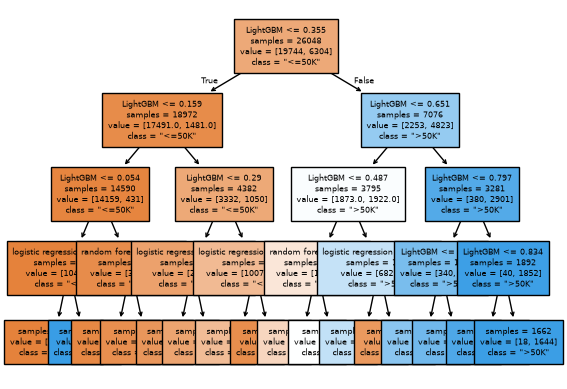

In [36]:
plot_tree(stacking_dt_model.final_estimator_, 
                 feature_names=ensemble_names,
                 class_names=['"<=50K"', '">50K"'],          
                 filled=True,
                 impurity=False,
                 fontsize=6);

## Takeaways and questions

| Method | How predictions combine |
|---|---|
| Random forest | Average independently randomized trees |
| Boosting | Add successive learned corrections |
| Voting | Combine labels or probabilities using fixed rules |
| Stacking | Learn a combination from out-of-fold predictions |

- Why does averaging identical mistakes fail to help?
- How do adding forest trees and adding boosting rounds differ?
- Why must preprocessing be inside every base pipeline?
- What are the distinct roles of inner and outer CV in stacking?
- When might a simpler model be preferable despite a slightly lower validation score?

The test set remains reserved. Choose the approach using validation results and practical costs before evaluating it once on the test set.